## 1. Set Environment

In [1]:
from pathlib import Path
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors, Crippen

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV,
    ParameterGrid
)
from sklearn.preprocessing import StandardScaler
from scipy.stats import ttest_ind
from statsmodels.nonparametric.smoothers_lowess import lowess
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.linear_model import Ridge
from sklearn.kernel_ridge import KernelRidge

RANDOM_STATE = 0
SPLIT_RANDOM_STATE = 0
TARGET = "exp"

FEATURES = [
    "MW",
    "TPSA",
    "HBD",
    "AromaticRings",
    "FractionCSP3",
    "RotatableBonds"
]

FEATURE_SETS = {
    "base": FEATURES.copy(),
    "plus_LogP": FEATURES + ["MolLogP"]
}

ALL_FEATURES = FEATURE_SETS["plus_LogP"]
EDA_COLUMNS = ALL_FEATURES + [TARGET]
GROUP_ORDER = ["≤500 Da", ">500 Da"]

OUTPUT_DIR = Path("final_project_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

LABELS = {
    "MW": "MW (Da)",
    "TPSA": "TPSA (Å²)",
    "HBD": "HBD (count)",
    "AromaticRings": "Aromatic rings (count)",
    "FractionCSP3": "Fraction Csp³ (dimensionless)",
    "RotatableBonds": "Rotatable bonds (count)",
    "MolLogP": "Calculated LogP (dimensionless)",
    TARGET: r"Experimental $\log D_{7.4}$ (dimensionless)"
}

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300

## 2. Data Loading and Cleaning

In [2]:
url = (
    "https://deepchemdata.s3-us-west-1.amazonaws.com/"
    "datasets/Lipophilicity.csv"
)

df_orig = pd.read_csv(url)
df = df_orig.copy()

required_columns = ["CMPD_CHEMBLID", "smiles", TARGET]

assert set(required_columns).issubset(df.columns), (
    "Missing required columns."
)
assert df.index.is_unique

print("Original shape:", df.shape)
display(df.head())

print("\nMissing values:")
display(df.isna().sum())

print("\nData types:")
display(df.dtypes)

print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate SMILES:", df["smiles"].duplicated().sum())

n_before = len(df)

# Clean target values
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
df[TARGET] = df[TARGET].replace([np.inf, -np.inf], np.nan)

df = df.dropna(subset=["smiles", TARGET]).copy()
df["smiles"] = df["smiles"].astype(str).str.strip()
df = df.loc[df["smiles"].ne("")].copy()


def parse_smiles(smiles):
    try:
        return Chem.MolFromSmiles(smiles)
    except (TypeError, ValueError):
        return None


df["mol"] = df["smiles"].apply(parse_smiles)

invalid_count = df["mol"].isna().sum()
print("Invalid SMILES:", invalid_count)

# Remove invalid molecules before canonicalization
df = df.loc[df["mol"].notna()].copy()
df["canonical_smiles"] = df["mol"].apply(Chem.MolToSmiles)

duplicate_mask = df["canonical_smiles"].duplicated(keep=False)

print("Rows belonging to duplicate molecules:", duplicate_mask.sum())

if duplicate_mask.any():
    display(
        df.loc[
            duplicate_mask,
            ["CMPD_CHEMBLID", "canonical_smiles", TARGET]
        ].sort_values("canonical_smiles")
    )
    raise ValueError(
        "Review duplicate molecules before splitting the data."
    )

print("Removed rows:", n_before - len(df))
print("Cleaned shape:", df.shape)

Original shape: (4200, 3)


,CMPD_CHEMBLID,exp,smiles
0,CHEMBL596271,3.54,Cn1c(CN2CCN(CC2)c3ccc(Cl)cc3)nc4ccccc14
1,CHEMBL1951080,-1.18,COc1cc(OC)c(cc1NC(=O)CSCC(=O)O)S(=O)(=O)N2C(C)...
2,CHEMBL1771,3.69,COC(=O)[C@@H](N1CCc2sccc2C1)c3ccccc3Cl
3,CHEMBL234951,3.37,OC[C@H](O)CN1C(=O)C(Cc2ccccc12)NC(=O)c3cc4cc(C...
4,CHEMBL565079,3.10,Cc1cccc(C[C@H](NC(=O)c2cc(nn2C)C(C)(C)C)C(=O)N...



Missing values:


CMPD_CHEMBLID    0
exp              0
smiles           0
dtype: int64


Data types:


CMPD_CHEMBLID     object
exp              float64
smiles            object
dtype: object

Exact duplicate rows: 0
Duplicate SMILES: 0
Invalid SMILES: 0
Rows belonging to duplicate molecules: 0
Removed rows: 0
Cleaned shape: (4200, 5)


## 3. Molecular Descriptor Calculation

In [3]:
def calculate_descriptors(mol):
    return {
        "MW": Descriptors.MolWt(mol),
        "TPSA": rdMolDescriptors.CalcTPSA(mol),
        "HBD": rdMolDescriptors.CalcNumHBD(mol),
        "AromaticRings": rdMolDescriptors.CalcNumAromaticRings(mol),
        "FractionCSP3": rdMolDescriptors.CalcFractionCSP3(mol),
        "RotatableBonds": rdMolDescriptors.CalcNumRotatableBonds(mol),
        "MolLogP": Crippen.MolLogP(mol)
    }


descriptor_df = pd.DataFrame(
    df["mol"].apply(calculate_descriptors).tolist(),
    index=df.index
)

# Safe to rerun: replace existing descriptor columns
df = df.drop(columns=ALL_FEATURES, errors="ignore")
df = df.join(descriptor_df)

assert df.columns.is_unique

for column in EDA_COLUMNS:
    df[column] = pd.to_numeric(df[column], errors="raise")

df[EDA_COLUMNS] = df[EDA_COLUMNS].replace(
    [np.inf, -np.inf], np.nan
)

assert df[TARGET].notna().all(), "Missing target values."
assert df["MW"].notna().all(), "Missing MW values."
assert df["MW"].gt(0).all(), "MW must be positive."

df["MW_group"] = np.where(
    df["MW"] <= 500,
    "≤500 Da",
    ">500 Da"
)

print("Missing values after descriptor calculation:")
display(df[EDA_COLUMNS].isna().sum())

display(df[["CMPD_CHEMBLID"] + ALL_FEATURES].head())

Missing values after descriptor calculation:


MW                0
TPSA              0
HBD               0
AromaticRings     0
FractionCSP3      0
RotatableBonds    0
MolLogP           0
exp               0
dtype: int64

,CMPD_CHEMBLID,MW,TPSA,HBD,AromaticRings,FractionCSP3,RotatableBonds,MolLogP
0,CHEMBL596271,340.858,24.30,0,3,0.315789,3,3.5489
1,CHEMBL1951080,494.591,122.24,2,2,0.363636,9,2.9901
2,CHEMBL1771,321.829,29.54,0,2,0.312500,3,3.6739
3,CHEMBL234951,419.890,105.66,4,3,0.263158,5,1.9237
4,CHEMBL565079,381.480,99.81,2,2,0.428571,6,2.0069


## 4. Development/Test Split and Cross-Validation Folds

In [4]:
# 85% development (five-fold CV), 15% held-out test; stratify by MW group.
df_dev, df_test = train_test_split(
    df, test_size=0.15, random_state=SPLIT_RANDOM_STATE,
    stratify=df["MW_group"]
)

dev_indices = df_dev.index.copy()
test_indices = df_test.index.copy()

assert len(dev_indices.intersection(test_indices)) == 0
assert set(dev_indices).union(test_indices) == set(df.index)

data_final = df.copy()
data_final["split"] = "development"
data_final.loc[test_indices, "split"] = "test"

# Keep original row IDs for traceability
data_final["source_row"] = data_final.index

dev = data_final.loc[dev_indices].copy().reset_index(drop=True)
test = data_final.loc[test_indices].copy().reset_index(drop=True)

assert set(dev["canonical_smiles"]).isdisjoint(
    set(test["canonical_smiles"])
)

group_counts = dev["MW_group"].value_counts().reindex(
    GROUP_ORDER, fill_value=0
)
assert group_counts.min() >= 5

splitter = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

CV_SPLITS = list(
    splitter.split(dev[FEATURES], dev["MW_group"])
)

dev["cv_fold"] = -1
test["cv_fold"] = -1

for fold, (_, valid_positions) in enumerate(CV_SPLITS):
    dev.loc[valid_positions, "cv_fold"] = fold

assert dev["cv_fold"].ge(0).all()

shared_columns = [
    "source_row",
    "CMPD_CHEMBLID",
    "canonical_smiles",
    TARGET,
    *ALL_FEATURES,
    "MW_group",
    "split",
    "cv_fold"
]

shared_data = pd.concat(
    [dev[shared_columns], test[shared_columns]],
    ignore_index=True
)

shared_data.to_csv(
    OUTPUT_DIR / "shared_data_and_folds.csv",
    index=False
)

split_counts = pd.crosstab(
    shared_data["split"], shared_data["MW_group"]
).reindex(columns=GROUP_ORDER)

display(split_counts)
split_counts.to_csv(OUTPUT_DIR / "split_counts.csv")

print("Development:", len(dev))
print("Test:", len(test))

MW_group,≤500 Da,>500 Da
split,,
development,3150,420
test,556,74


Development: 3570
Test: 630


## 5. Exploratory Data Analysis
- Use development data for EDA.
- Compare all descriptors and logD between MW groups with summary tables, boxplots, and separately normalized histograms.
- MW's right tail is investigated with IQR fences, maximum and skewness; valid observations are retained. IQR flags are especially limited for discrete and bounded descriptors.
- LogP is newly added compared to our proposal due to our further research. It is retained as a SMILES-derived RDKit Crippen descriptor and evaluated by a with/without feature comparison. It estimates partitioning of the represented structure, whereas the measured target is logD at pH 7.4, which also depends on ionization. They are related but not interchangeable. Structure-derived calculated LogP does not directly use the measured target. Compare its incremental value using development CV rather than discarding it for correlation or choosing it on test results.

,variable,group,count,mean,std,min,25%,50%,75%,max,IQR
0,MW,All development,3570.0,383.567,107.438,113.160,306.802,388.876,456.918,1620.693,150.116
1,TPSA,All development,3570.0,78.788,32.337,0.000,56.380,79.810,98.310,702.020,41.930
2,HBD,All development,3570.0,1.619,1.171,0.000,1.000,1.000,2.000,22.000,1.000
3,AromaticRings,All development,3570.0,2.618,0.964,0.000,2.000,3.000,3.000,6.000,1.000
4,FractionCSP3,All development,3570.0,0.302,0.180,0.000,0.167,0.296,0.412,1.000,0.245
5,RotatableBonds,All development,3570.0,5.234,2.915,0.000,3.000,5.000,7.000,35.000,4.000
6,MolLogP,All development,3570.0,3.290,1.319,-5.622,2.444,3.300,4.128,10.343,1.683
7,exp,All development,3570.0,2.194,1.204,-1.500,1.410,2.370,3.110,4.500,1.700
8,MW,≤500 Da,3150.0,360.934,87.552,113.160,295.488,374.400,432.410,499.962,136.922
9,TPSA,≤500 Da,3150.0,75.110,28.031,0.000,53.610,76.985,94.660,170.830,41.050


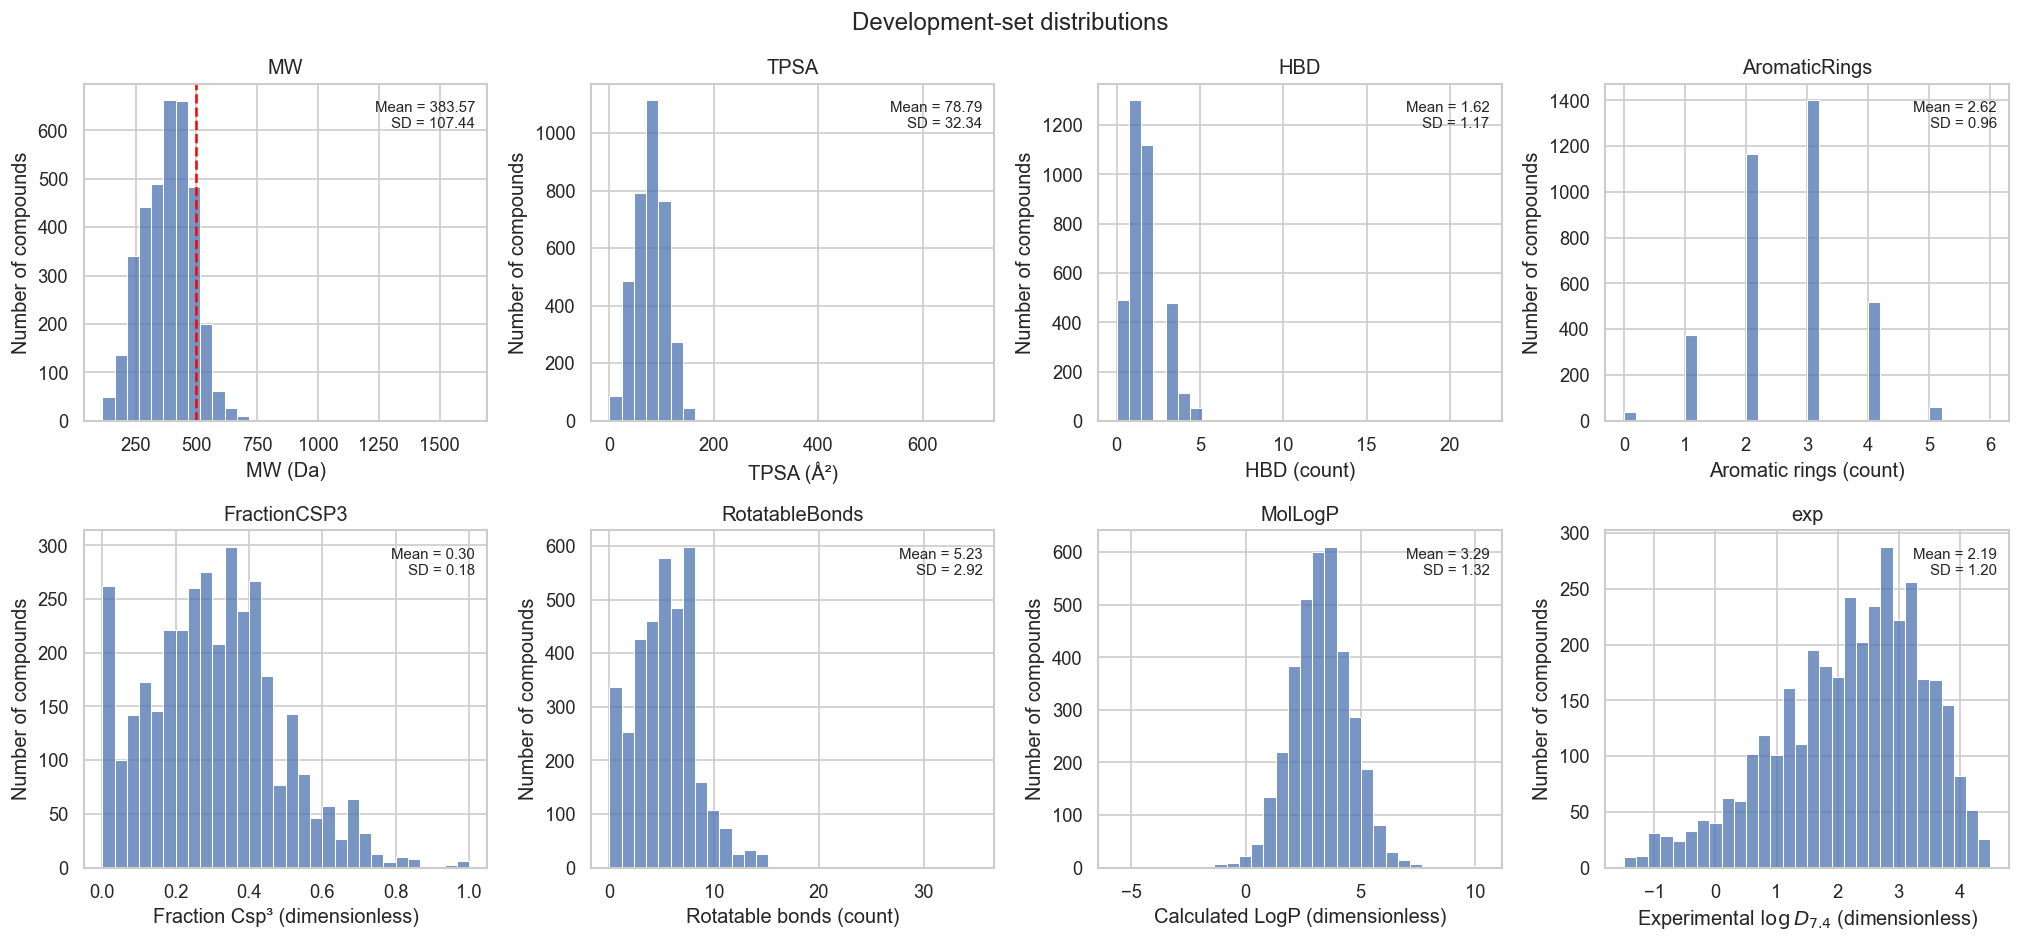

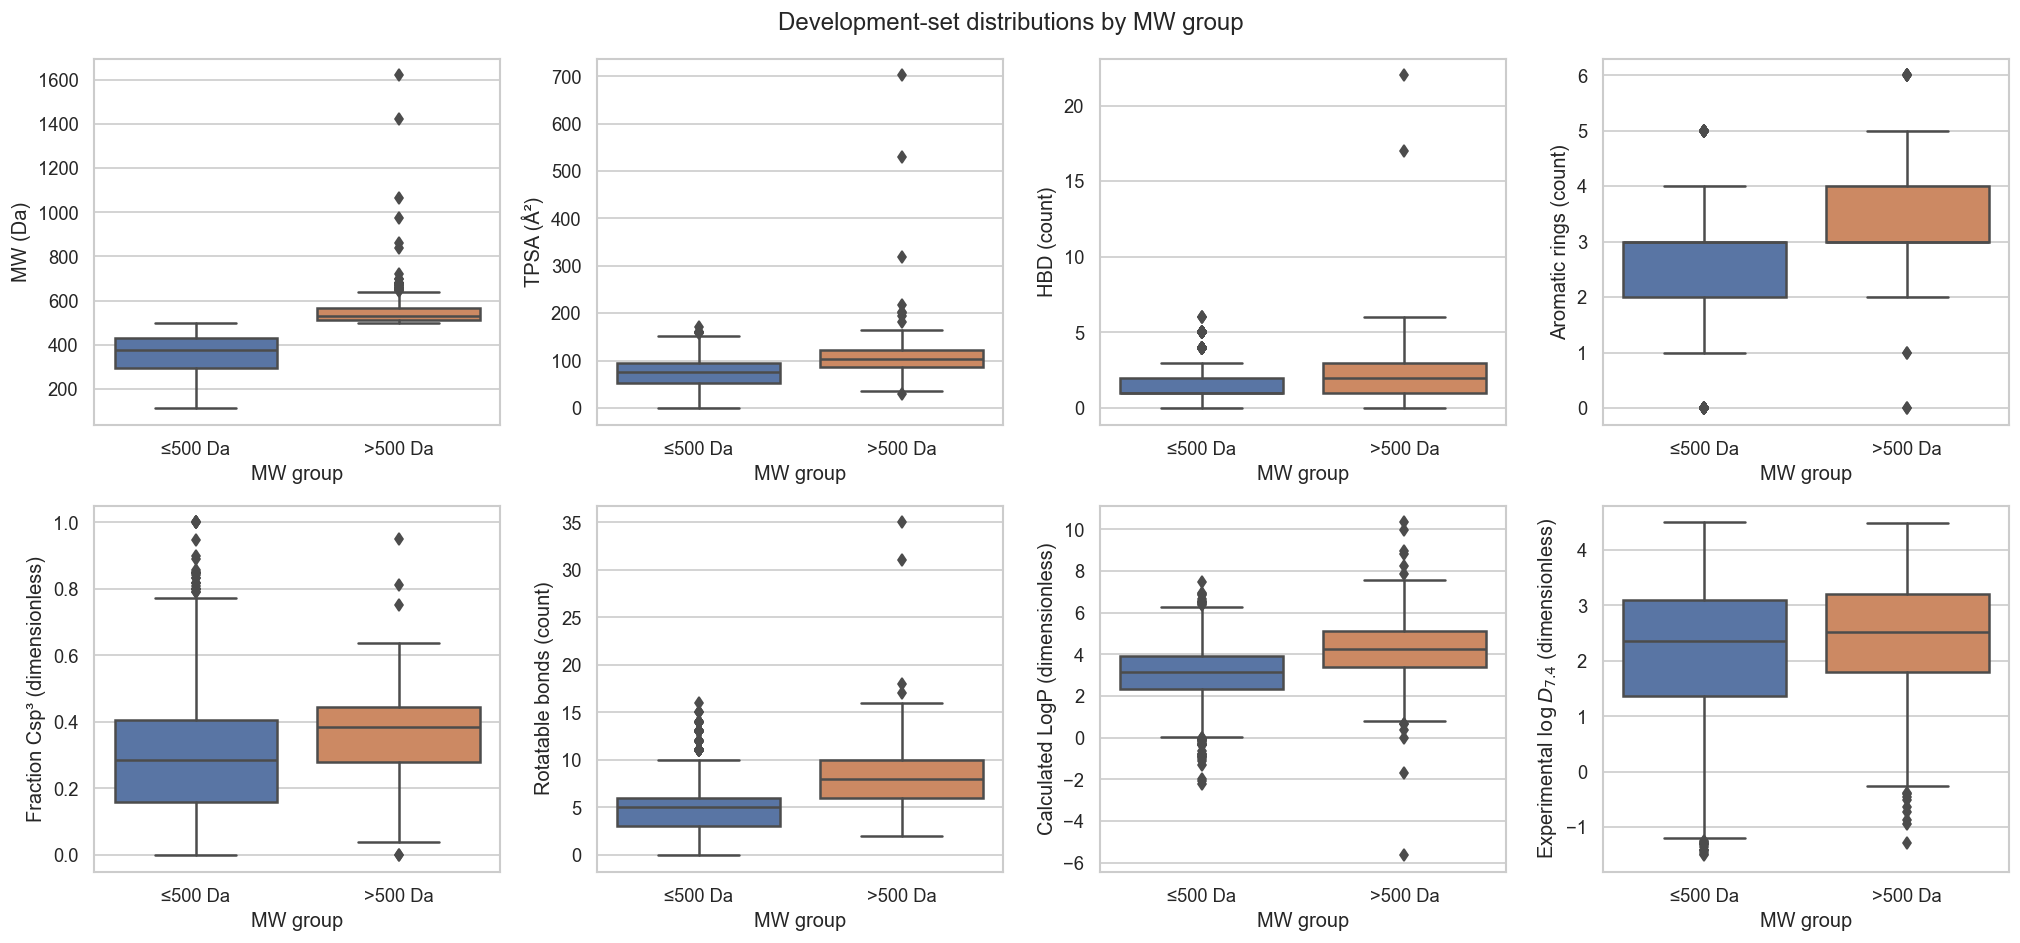

,variable,lower_fence,upper_fence,flagged_n,flagged_percent
0,MW,81.629,682.092,9,0.252
1,TPSA,-6.515,161.205,13,0.364
2,HBD,-0.500,3.500,175,4.902
3,AromaticRings,0.500,4.500,107,2.997
4,FractionCSP3,-0.201,0.779,30,0.840
5,RotatableBonds,-3.000,13.000,33,0.924
6,MolLogP,-0.081,6.653,51,1.429
7,exp,-1.140,5.660,19,0.532


,CMPD_CHEMBLID,canonical_smiles,MW,TPSA,HBD,AromaticRings,FractionCSP3,RotatableBonds,MolLogP,exp
3144,CHEMBL387675,CCCCCCCCCC(=O)N[C@@H](Cc1c[nH]c2ccccc12)C(=O)N...,1620.693,702.02,22,3,0.527778,35,-5.62180,-0.94
445,CHEMBL1200558,CC[C@H](C)[C@H](N)C1=N[C@H](C(=O)N[C@@H](CC(C)...,1422.720,530.87,17,2,0.636364,31,-1.67760,-0.46
552,CHEMBL2170837,CCn1c(C)c(C(=O)O)c(-c2cccc(N3CCN(c4ccc(NS(=O)(...,1065.703,164.52,4,6,0.326923,18,10.34252,4.20
1143,CHEMBL443684,CC1(C)CCC(c2ccc(Cl)cc2)=C(CN2CCN(c3ccc(C(=O)NS...,974.634,128.36,2,4,0.425532,16,8.83320,0.64
613,CHEMBL3545252,CC(=O)O[C@@]12CO[C@@H]1C[C@H](O)[C@@]1(C)C(=O)...,861.935,318.95,5,2,0.558140,8,0.78550,3.40
586,CHEMBL1214185,CC[C@H]1OC(=O)[C@H](C)[C@@H](O[C@H]2C[C@@](C)(...,837.058,216.89,5,0,0.951220,13,2.20960,1.80
3330,CHEMBL163,CC(C)c1nc(CN(C)C(=O)N[C@H](C(=O)N[C@@H](Cc2ccc...,720.962,145.78,4,4,0.432432,17,5.90520,4.30
2000,CHEMBL437765,CO[C@H]1/C=C/O[C@@]2(C)Oc3c(C)c(O)c4c(O)c(cc(O...,697.778,201.31,6,2,0.486486,2,4.75412,1.19
81,CHEMBL74380,COC1/C=C/OC2(C)Oc3c(C)c(O)c4c(c3C2=O)C(=O)C=C(...,695.762,194.99,4,1,0.486486,2,3.63032,0.70


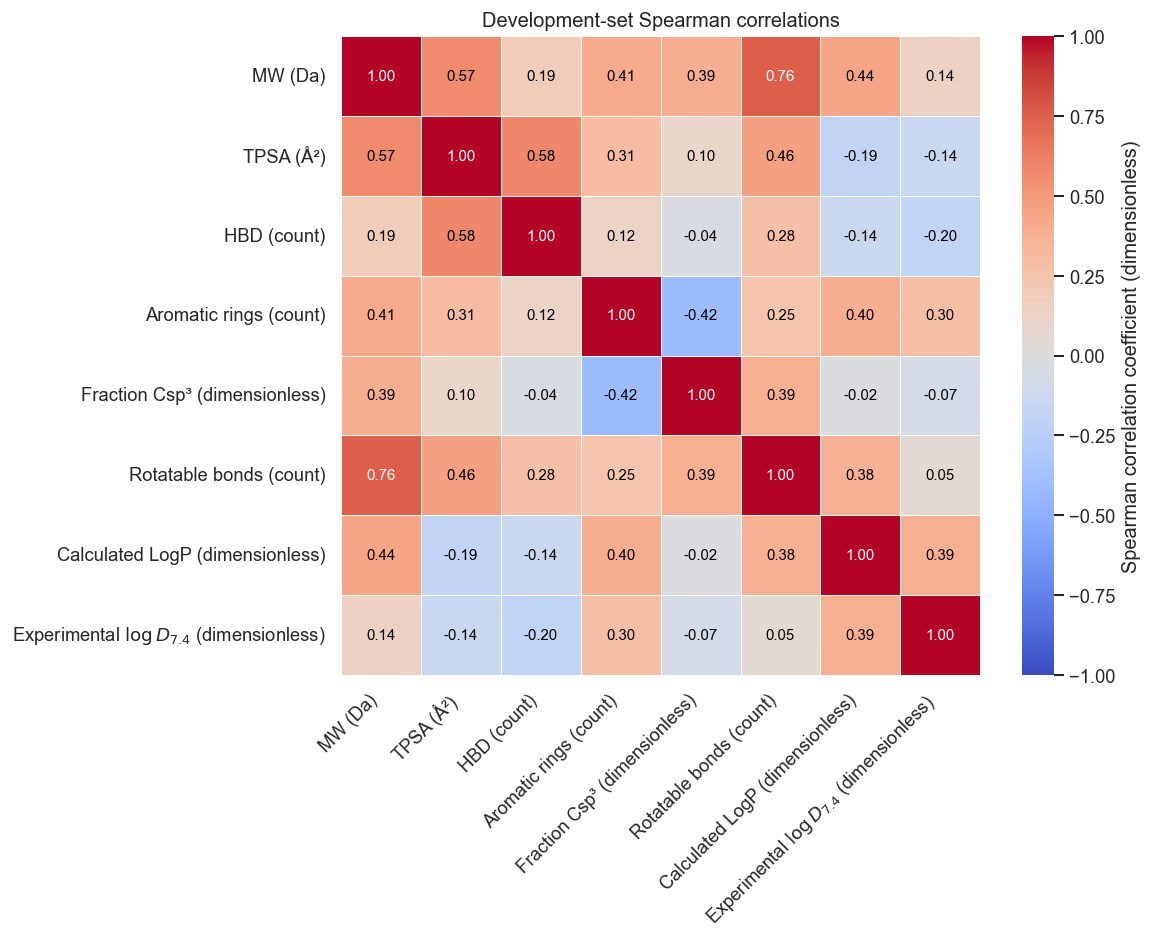

Highly correlated feature pairs:


MW  RotatableBonds    0.757019
Name: Spearman_rho, dtype: float64

HBD              -0.196144
TPSA             -0.143653
FractionCSP3     -0.069768
RotatableBonds    0.048771
MW                0.142878
AromaticRings     0.295057
MolLogP           0.385000
Name: exp, dtype: float64

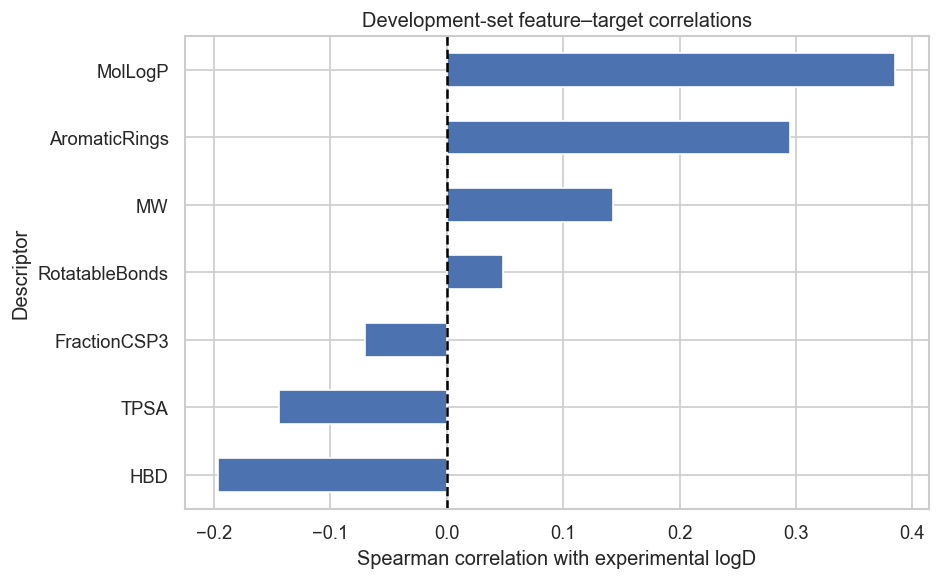

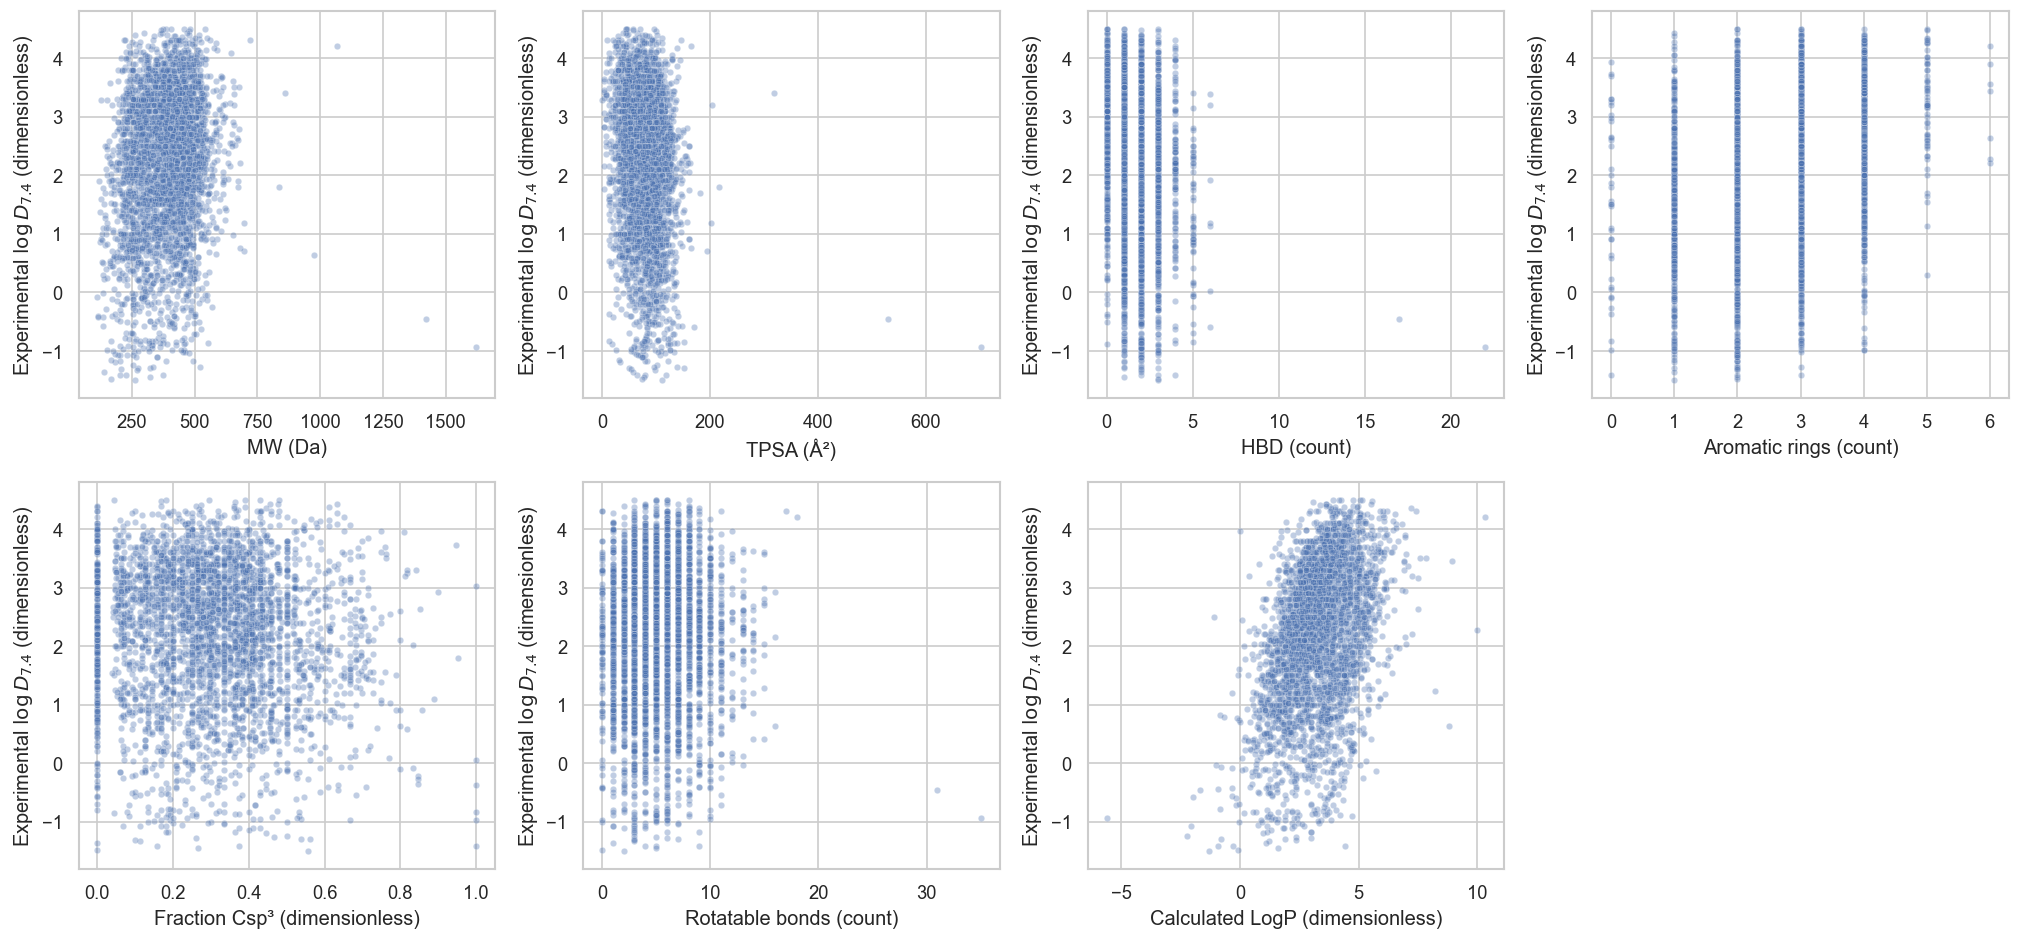

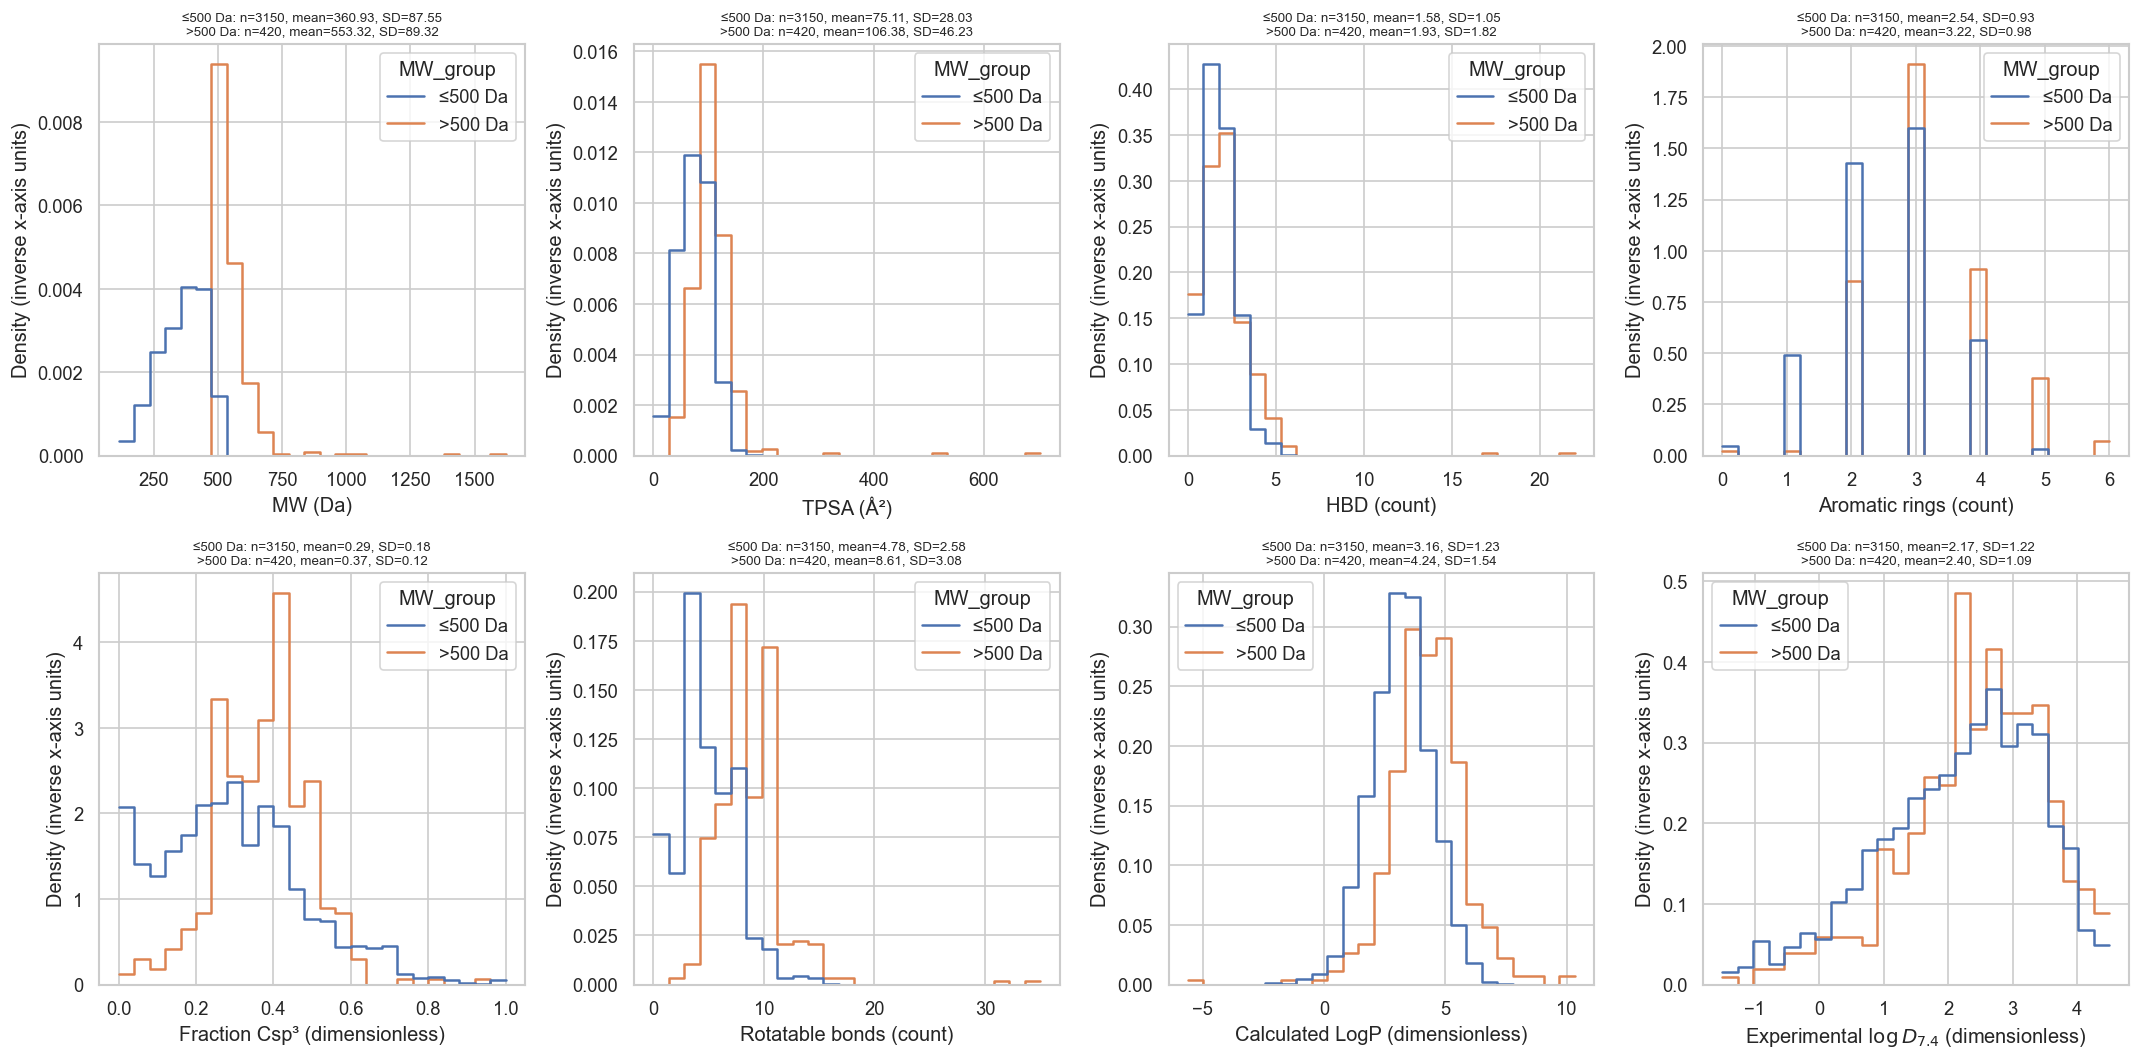

,group,n,tail_n,tail_percent,max_MW_Da,MW_skewness
0,≤500 Da,3150,0,0.000000,499.962,-0.436116
1,>500 Da,420,9,2.142857,1620.693,7.293698


IQR flags are inspection criteria, not proof of measurement errors.
Retain valid large molecules; removing them would bias the MW comparison.


In [5]:
# Overall and group-specific summary statistics
summary_tables = []

groups = [
    ("All development", dev),
    *[(group, dev.loc[dev["MW_group"] == group])
      for group in GROUP_ORDER]
]

for group_name, group_data in groups:
    table = group_data[EDA_COLUMNS].describe().T
    table["IQR"] = table["75%"] - table["25%"]
    table.insert(0, "group", group_name)
    table.index.name = "variable"
    summary_tables.append(table.reset_index())

group_summary = pd.concat(summary_tables, ignore_index=True)
display(group_summary.round(3))

group_summary.to_csv(
    OUTPUT_DIR / "development_group_summary.csv",
    index=False
)


# Overall development distributions
fig, axes = plt.subplots(2, 4, figsize=(17, 8))

for ax, column in zip(axes.flat, EDA_COLUMNS):
    sns.histplot(data=dev, x=column, bins=30, ax=ax)

    ax.set_xlabel(LABELS[column])
    ax.set_ylabel("Number of compounds")
    ax.set_title(column)

    ax.text(
        0.97, 0.95,
        f"Mean = {dev[column].mean():.2f}\n"
        f"SD = {dev[column].std():.2f}",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=9
    )

    if column == "MW":
        ax.axvline(500, color="red", linestyle="--")

fig.suptitle("Development-set distributions")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "development_distributions.png")
plt.show()


# Distribution comparison between MW groups
fig, axes = plt.subplots(2, 4, figsize=(17, 8))

for ax, column in zip(axes.flat, EDA_COLUMNS):
    sns.boxplot(
        data=dev,
        x="MW_group",
        y=column,
        order=GROUP_ORDER,
        ax=ax
    )
    ax.set_xlabel("MW group")
    ax.set_ylabel(LABELS[column])

fig.suptitle("Development-set distributions by MW group")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "group_distributions.png")
plt.show()


# IQR outlier flags: inspection only, no automatic removal
outlier_records = []

for column in EDA_COLUMNS:
    q1 = dev[column].quantile(0.25)
    q3 = dev[column].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    observed = dev[column].notna()
    flag = (dev[column] < lower) | (dev[column] > upper)

    outlier_records.append({
        "variable": column,
        "lower_fence": lower,
        "upper_fence": upper,
        "flagged_n": int(flag.sum()),
        "flagged_percent": (
            100 * flag[observed].mean() if observed.any() else np.nan
        )
    })

outlier_summary = pd.DataFrame(outlier_records)
display(outlier_summary.round(3))

outlier_summary.to_csv(
    OUTPUT_DIR / "outlier_summary.csv",
    index=False
)

mw_upper = outlier_summary.loc[
    outlier_summary["variable"] == "MW", "upper_fence"
].iloc[0]

mw_tail = dev.loc[
    dev["MW"] > mw_upper,
    ["CMPD_CHEMBLID", "canonical_smiles"] + EDA_COLUMNS
].sort_values("MW", ascending=False)

display(mw_tail)
mw_tail.to_csv(OUTPUT_DIR / "MW_tail_for_review.csv", index=False)


# Correlation heatmap: descriptors and target
corr_final = dev[EDA_COLUMNS].corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    corr_final,
    annot=False,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Spearman correlation coefficient (dimensionless)"},
    ax=ax
)

for row in range(corr_final.shape[0]):
    for col in range(corr_final.shape[1]):
        value = corr_final.iloc[row, col]
        ax.text(
            col + 0.5,
            row + 0.5,
            f"{value:.2f}" if pd.notna(value) else "N/A",
            ha="center",
            va="center",
            color="white" if abs(value) >= 0.65 else "black",
            fontsize=9
        )

ax.set_xticklabels([LABELS[c] for c in corr_final.columns], rotation=45, ha="right")
ax.set_yticklabels([LABELS[c] for c in corr_final.index], rotation=0)
ax.set_title("Development-set Spearman correlations")

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "correlation_heatmap.png")
plt.show()

# Unique highly correlated feature pairs; exclude self-correlations
corr_features = dev[ALL_FEATURES].corr(method="spearman")
upper_mask = np.triu(
    np.ones(corr_features.shape, dtype=bool), k=1
)

high_corr_pairs = (
    corr_features.where(upper_mask)
    .stack()
    .rename("Spearman_rho")
)
high_corr_pairs = high_corr_pairs.loc[
    high_corr_pairs.abs() >= 0.75
]

print("Highly correlated feature pairs:")
display(high_corr_pairs)


# Feature-target correlations
corr_target = (
    corr_final[TARGET]
    .drop(TARGET)
    .sort_values()
)

display(corr_target)

fig, ax = plt.subplots(figsize=(8, 5))
corr_target.plot.barh(ax=ax)
ax.axvline(0, color="black", linestyle="--")
ax.set_xlabel("Spearman correlation with experimental logD")
ax.set_ylabel("Descriptor")
ax.set_title("Development-set feature–target correlations")

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "feature_target_correlations.png")
plt.show()


# Feature-target scatterplots
fig, axes = plt.subplots(2, 4, figsize=(17, 8))

for ax, column in zip(axes.flat, ALL_FEATURES):
    sns.scatterplot(
        data=dev,
        x=column,
        y=TARGET,
        alpha=0.35,
        s=15,
        ax=ax
    )
    ax.set_xlabel(LABELS[column])
    ax.set_ylabel(LABELS[TARGET])

for ax in axes.flat[len(ALL_FEATURES):]:
    ax.set_visible(False)

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "feature_target_scatterplots.png")
plt.show()

# Normalize each MW group's histogram separately to compare unequal groups.
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, column in zip(axes.flat, EDA_COLUMNS):
    sns.histplot(data=dev, x=column, hue="MW_group", hue_order=GROUP_ORDER,
                 bins=25, stat="density", common_norm=False,
                 element="step", fill=False, ax=ax)
    ax.set_xlabel(LABELS[column])
    ax.set_ylabel("Density (inverse x-axis units)")
    lines = []
    for group in GROUP_ORDER:
        v = dev.loc[dev["MW_group"].eq(group), column]
        lines.append(f"{group}: n={v.count()}, mean={v.mean():.2f}, SD={v.std():.2f}")
    ax.set_title("\n".join(lines), fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "group_density_distributions.png")
plt.show()

tail_rows = []
for group in GROUP_ORDER:
    block = dev.loc[dev["MW_group"].eq(group)]
    flag = block["MW"] > mw_upper
    tail_rows.append({"group": group, "n": len(block),
                      "tail_n": int(flag.sum()), "tail_percent": 100*flag.mean(),
                      "max_MW_Da": block["MW"].max(), "MW_skewness": block["MW"].skew()})
tail_summary = pd.DataFrame(tail_rows)
display(tail_summary)
tail_summary.to_csv(OUTPUT_DIR / "MW_tail_by_group.csv", index=False)
print("IQR flags are inspection criteria, not proof of measurement errors.")
print("Retain valid large molecules; removing them would bias the MW comparison.")


## 6. Model Training and Hyperparameter Tuning
- Median imputation is inside each pipeline. Ridge and RBF Kernel Ridge also use StandardScaler inside CV; Random Forest does not require scaling. All candidates share CV folds and are ranked by mean CV RMSE. CV scores used for tuning are model-selection estimates; the holdout provides the final evaluation.
- References: [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html), [KernelRidge](https://scikit-learn.org/stable/modules/generated/sklearn.kernel_ridge.KernelRidge.html).

In [6]:
SCORING = {
    "RMSE": "neg_root_mean_squared_error",
    "MAE": "neg_mean_absolute_error",
    "R2": "r2"
}

RF_PARAMETERS = {
    "model__n_estimators": [200, 400, 600],
    "model__max_depth": [None, 5, 10, 20],
    "model__min_samples_leaf": [1, 2, 5, 10],
    "model__max_features": [0.7, 1.0]
}

searches = {}
candidate_features = {}


def run_search(
    name,
    estimator,
    parameter_space,
    feature_columns,
    scale=None
):
    # Automatically standardize Ridge and Kernel Ridge.
    # Existing calls without scale=True will also work.
    if scale is None:
        scale = isinstance(estimator, (Ridge, KernelRidge))

    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler() if scale else "passthrough"),
        ("model", estimator)
    ])

    n_combinations = len(ParameterGrid(parameter_space))

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=parameter_space,
        n_iter=min(24, n_combinations),
        scoring=SCORING,
        refit="RMSE",
        cv=CV_SPLITS,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        return_train_score=True,
        error_score="raise"
    )

    search.fit(dev[feature_columns], dev[TARGET])

    searches[name] = search
    candidate_features[name] = feature_columns.copy()

    pd.DataFrame(search.cv_results_).to_csv(
        OUTPUT_DIR / f"{name}_cv_results.csv",
        index=False
    )

    joblib.dump(
        {
            "model": search.best_estimator_,
            "features": feature_columns.copy()
        },
        OUTPUT_DIR / f"{name}_model.joblib"
    )

    print(name)
    print("Scaler:", search.best_estimator_.named_steps["scaler"])
    print("Best parameters:", search.best_params_)
    print("Best CV RMSE:", round(-search.best_score_, 4))
    print()


# Dummy baseline
run_search(
    name="Dummy",
    estimator=DummyRegressor(strategy="mean"),
    parameter_space={},
    feature_columns=FEATURES
)

# Random Forest: with and without calculated LogP
for feature_name, columns in FEATURE_SETS.items():
    run_search(
        name=f"RF_{feature_name}",
        estimator=RandomForestRegressor(
            random_state=RANDOM_STATE,
            n_jobs=1
        ),
        parameter_space=RF_PARAMETERS,
        feature_columns=columns
    )

Dummy
Scaler: passthrough
Best parameters: {}
Best CV RMSE: 1.2037

RF_base
Scaler: passthrough
Best parameters: {'model__n_estimators': 600, 'model__min_samples_leaf': 1, 'model__max_features': 0.7, 'model__max_depth': None}
Best CV RMSE: 0.9246

RF_plus_LogP
Scaler: passthrough
Best parameters: {'model__n_estimators': 600, 'model__min_samples_leaf': 1, 'model__max_features': 0.7, 'model__max_depth': None}
Best CV RMSE: 0.8913



In [7]:
# Hyperparameters to tune for Ridge
ridge_params = {
    "model__alpha": [0.1, 1.0, 10.0, 100.0]
}

# Hyperparameters to tune for Kernel Ridge
kr_params = {
    "model__alpha": [0.1, 1.0, 10.0],
    "model__gamma": [0.01, 0.1, 1.0]
}

# Scenario 1: Ridge regression WITHOUT logP (base)
run_search(
    name="Ridge_base",
    estimator=Ridge(random_state=RANDOM_STATE),
    parameter_space=ridge_params,
    feature_columns=FEATURE_SETS["base"]
)

# Scenario 2: Ridge regression WITH logP
run_search(
    name="Ridge_plus_LogP",
    estimator=Ridge(random_state=RANDOM_STATE),
    parameter_space=ridge_params,
    feature_columns=FEATURE_SETS["plus_LogP"]
)

# Scenario 1: Kernel Ridge WITHOUT logP (base)
run_search(
    name="KernelRidge_base",
    estimator=KernelRidge(kernel="rbf"),
    parameter_space=kr_params,
    feature_columns=FEATURE_SETS["base"]
)

# Scenario 2: Kernel Ridge WITH logP
run_search(
    name="KernelRidge_plus_LogP",
    estimator=KernelRidge(kernel="rbf"),
    parameter_space=kr_params,
    feature_columns=FEATURE_SETS["plus_LogP"]
)

Ridge_base
Scaler: StandardScaler()
Best parameters: {'model__alpha': 10.0}
Best CV RMSE: 1.079

Ridge_plus_LogP
Scaler: StandardScaler()
Best parameters: {'model__alpha': 100.0}
Best CV RMSE: 1.0622

KernelRidge_base
Scaler: StandardScaler()
Best parameters: {'model__gamma': 0.1, 'model__alpha': 0.1}
Best CV RMSE: 1.0007

KernelRidge_plus_LogP
Scaler: StandardScaler()
Best parameters: {'model__gamma': 0.1, 'model__alpha': 0.1}
Best CV RMSE: 0.9585



## 7. Cross-Validation Comparison and Model Selection

In [8]:
comparison_rows = []

for name, search in searches.items():
    i = search.best_index_
    results = search.cv_results_

    comparison_rows.append({
        "model": name,
        "train_RMSE": -results["mean_train_RMSE"][i],
        "CV_RMSE": -results["mean_test_RMSE"][i],
        "CV_RMSE_SD": results["std_test_RMSE"][i],
        "train_MAE": -results["mean_train_MAE"][i],
        "CV_MAE": -results["mean_test_MAE"][i],
        "train_R2": results["mean_train_R2"][i],
        "CV_R2": results["mean_test_R2"][i],
        "best_parameters": str(search.best_params_)
    })

cv_comparison = (
    pd.DataFrame(comparison_rows)
    .sort_values("CV_RMSE")
    .reset_index(drop=True)
)

display(cv_comparison.round(4))

cv_comparison.to_csv(
    OUTPUT_DIR / "CV_model_comparison.csv",
    index=False
)


logp_rows = []
indexed = cv_comparison.set_index("model")
for family in ["Ridge", "KernelRidge", "RF"]:
    a = indexed.loc[f"{family}_base", "CV_RMSE"]
    b = indexed.loc[f"{family}_plus_LogP", "CV_RMSE"]
    logp_rows.append({"family": family, "base_CV_RMSE": a,
                      "plus_LogP_CV_RMSE": b, "improvement_with_LogP": a-b})
logp_comparison = pd.DataFrame(logp_rows)
display(logp_comparison.round(4))
logp_comparison.to_csv(OUTPUT_DIR / "LogP_ablation_CV.csv", index=False)

# Select across every scientific candidate using development CV only.
eligible = cv_comparison.loc[cv_comparison["model"].ne("Dummy")]
selected_name = eligible.iloc[0]["model"]
print("Model selected before test evaluation:", selected_name)
(OUTPUT_DIR / "selected_model.txt").write_text(selected_name, encoding="utf-8")


,model,train_RMSE,CV_RMSE,CV_RMSE_SD,train_MAE,CV_MAE,train_R2,CV_R2,best_parameters
0,RF_plus_LogP,0.3362,0.8913,0.0335,0.2561,0.6760,0.9220,0.4512,"{'model__n_estimators': 600, 'model__min_sampl..."
1,RF_base,0.3515,0.9246,0.0324,0.2695,0.7045,0.9147,0.4098,"{'model__n_estimators': 600, 'model__min_sampl..."
2,KernelRidge_plus_LogP,0.8743,0.9585,0.0268,0.6802,0.7509,0.4727,0.3655,"{'model__gamma': 0.1, 'model__alpha': 0.1}"
3,KernelRidge_base,0.9402,1.0007,0.0218,0.7403,0.7909,0.3901,0.3087,"{'model__gamma': 0.1, 'model__alpha': 0.1}"
4,Ridge_plus_LogP,1.0601,1.0622,0.0244,0.8528,0.8541,0.2246,0.2211,{'model__alpha': 100.0}
5,Ridge_base,1.0770,1.0790,0.0227,0.8686,0.8702,0.1998,0.1963,{'model__alpha': 10.0}
6,Dummy,1.2039,1.2037,0.0244,0.9766,0.9767,0.0000,-0.0002,{}


,family,base_CV_RMSE,plus_LogP_CV_RMSE,improvement_with_LogP
0,Ridge,1.0790,1.0622,0.0168
1,KernelRidge,1.0007,0.9585,0.0422
2,RF,0.9246,0.8913,0.0333


Model selected before test evaluation: RF_plus_LogP


12

## 8. Final Test Evaluation and Molecular-Weight Group Analysis

Overall test results:


,n,MAE,RMSE,R2
model,,,,
Dummy,630,0.9530,1.1971,-0.0020
Ridge_base,630,0.8545,1.0584,0.2166
Ridge_plus_LogP,630,0.8318,1.0304,0.2576
KernelRidge_base,630,0.7620,0.9817,0.3261
KernelRidge_plus_LogP,630,0.7046,0.9202,0.4078
RF_base,630,0.6527,0.8613,0.4812
RF_plus_LogP,630,0.6418,0.8453,0.5003


Test results by MW group:


,model,group,n,MAE,RMSE,R2
1,Dummy,≤500 Da,556,0.9866,1.2296,-0.0072
2,Dummy,>500 Da,74,0.7002,0.9163,-0.1412
4,Ridge_base,≤500 Da,556,0.8837,1.0883,0.2109
5,Ridge_base,>500 Da,74,0.6354,0.7987,0.1329
7,Ridge_plus_LogP,≤500 Da,556,0.8589,1.0574,0.2552
8,Ridge_plus_LogP,>500 Da,74,0.6278,0.7988,0.1327
10,KernelRidge_base,≤500 Da,556,0.7665,0.9815,0.3583
11,KernelRidge_base,>500 Da,74,0.7280,0.9834,-0.3145
13,KernelRidge_plus_LogP,≤500 Da,556,0.7063,0.9200,0.4362
14,KernelRidge_plus_LogP,>500 Da,74,0.6920,0.9223,-0.1563



MW-group MAE comparison for the CV-selected model:


,model,n_low_MW,n_high_MW,MAE_low_MW,MAE_high_MW,MAE_difference_high_minus_low,CI_95_lower,CI_95_upper
0,RF_plus_LogP,556,74,0.6556,0.5375,-0.1182,-0.2309,-0.0038


Difference = MAE (>500 Da) - MAE (≤500 Da)
Positive: larger absolute errors in the >500 Da group.
Negative: smaller absolute errors in the >500 Da group.
The 95% bootstrap CI excludes zero; the estimated group MAE difference has a consistent direction.

Results saved to: /Users/helenliu/Downloads/CHE1147-Team2-project-main/notebooks/final_project_results


,model,n_low_MW,n_high_MW,MAE_low_MW,MAE_high_MW,MAE_difference_high_minus_low,CI_95_lower,CI_95_upper,Welch_t,Welch_p_two_sided,alpha
0,RF_plus_LogP,556,74,0.65564,0.53747,-0.11817,-0.23088,-0.00378,-2.02858,0.04504,0.05


Reject equal group MAE at alpha=0.05.
Bootstrap CI describes uncertainty in the MAE difference; it is not a p-value.
Inference assumes independent test compounds and is conditional on this fitted model.
Chemical scaffold dependence and few high-MW compounds limit generalization.
A group difference does not prove an abrupt or causal boundary at 500 Da.


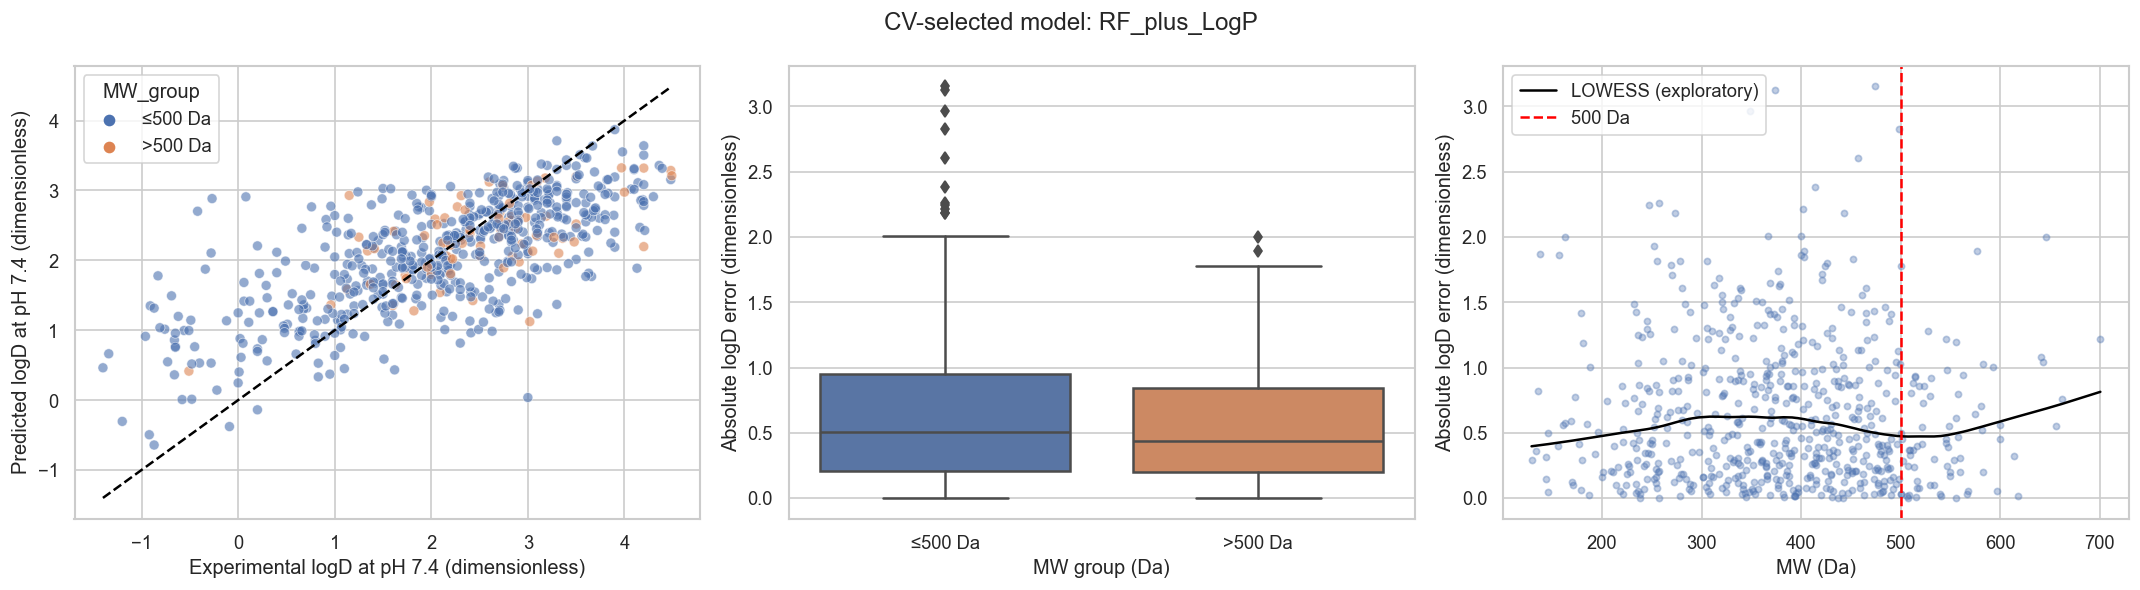

,n,MAE,SD
MW_group,,,
>500 Da,66,0.496701,0.423155
≤500 Da,205,0.653673,0.579744


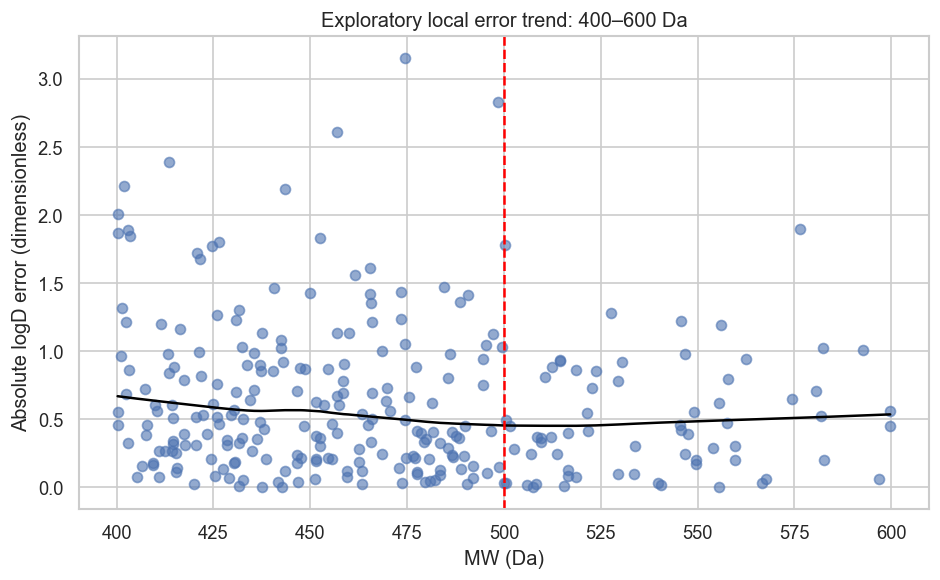

In [9]:
MY_MODELS = [
    "Dummy",
    "Ridge_base",
    "Ridge_plus_LogP",
    "KernelRidge_base",
    "KernelRidge_plus_LogP",
    "RF_base",
    "RF_plus_LogP"
]

my_test_predictions = {}
metric_rows = []

for name in MY_MODELS:
    feature_columns = candidate_features[name]
    fitted_model = searches[name].best_estimator_

    y_pred = fitted_model.predict(test[feature_columns])

    predictions = test[
        ["source_row", "CMPD_CHEMBLID", "MW", "MW_group"]
    ].copy()

    predictions["y_true"] = test[TARGET].to_numpy()
    predictions["y_pred"] = y_pred
    predictions["residual"] = (
        predictions["y_true"] - predictions["y_pred"]
    )
    predictions["absolute_error"] = predictions["residual"].abs()

    my_test_predictions[name] = predictions

    predictions.to_csv(
        OUTPUT_DIR / f"{name}_test_predictions.csv",
        index=False
    )

    evaluation_groups = [
        ("All test", predictions),
        *[
            (
                group,
                predictions.loc[predictions["MW_group"] == group]
            )
            for group in GROUP_ORDER
        ]
    ]

    for group_name, group_data in evaluation_groups:
        if group_data.empty:
            continue

        y_true = group_data["y_true"]
        y_hat = group_data["y_pred"]

        metric_rows.append({
            "model": name,
            "group": group_name,
            "n": len(group_data),
            "MAE": mean_absolute_error(y_true, y_hat),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_hat)),
            "R2": (
                r2_score(y_true, y_hat)
                if len(group_data) >= 2 and y_true.nunique() > 1
                else np.nan
            )
        })

my_test_metrics = pd.DataFrame(metric_rows)

overall_test = (
    my_test_metrics.loc[my_test_metrics["group"] == "All test"]
    .set_index("model")
    .loc[MY_MODELS, ["n", "MAE", "RMSE", "R2"]
]
)

group_test = my_test_metrics.loc[
    my_test_metrics["group"] != "All test"
].copy()

print("Overall test results:")
display(overall_test.round(4))

print("Test results by MW group:")
display(group_test.round(4))

my_test_metrics.to_csv(
    OUTPUT_DIR / "my_models_test_metrics.csv",
    index=False
)

selected_predictions = my_test_predictions[selected_name]


# Bootstrap CI for the selected model's group MAE difference.
# Difference = MAE (>500 Da) - MAE (≤500 Da).
low_errors = selected_predictions.loc[
    selected_predictions["MW_group"] == "≤500 Da",
    "absolute_error"
].to_numpy()

high_errors = selected_predictions.loc[
    selected_predictions["MW_group"] == ">500 Da",
    "absolute_error"
].to_numpy()

assert len(low_errors) >= 2 and len(high_errors) >= 2

rng = np.random.default_rng(RANDOM_STATE)
n_bootstrap = 10000
bootstrap_differences = np.empty(n_bootstrap)

for i in range(n_bootstrap):
    low_sample = rng.choice(
        low_errors, size=len(low_errors), replace=True
    )
    high_sample = rng.choice(
        high_errors, size=len(high_errors), replace=True
    )

    bootstrap_differences[i] = (
        high_sample.mean() - low_sample.mean()
    )

observed_difference = high_errors.mean() - low_errors.mean()
ci_lower, ci_upper = np.quantile(
    bootstrap_differences, [0.025, 0.975]
)

group_comparison = pd.DataFrame([{
    "model": selected_name,
    "n_low_MW": len(low_errors),
    "n_high_MW": len(high_errors),
    "MAE_low_MW": low_errors.mean(),
    "MAE_high_MW": high_errors.mean(),
    "MAE_difference_high_minus_low": observed_difference,
    "CI_95_lower": ci_lower,
    "CI_95_upper": ci_upper
}])

print("\nMW-group MAE comparison for the CV-selected model:")
display(group_comparison.round(4))

group_comparison.to_csv(
    OUTPUT_DIR / "MW_group_MAE_bootstrap.csv",
    index=False
)

print("Difference = MAE (>500 Da) - MAE (≤500 Da)")
print("Positive: larger absolute errors in the >500 Da group.")
print("Negative: smaller absolute errors in the >500 Da group.")

if ci_lower <= 0 <= ci_upper:
    print(
        "The 95% bootstrap CI includes zero; "
        "the direction of the group MAE difference is uncertain."
    )
else:
    print(
        "The 95% bootstrap CI excludes zero; "
        "the estimated group MAE difference has a consistent direction."
    )

print("\nResults saved to:", OUTPUT_DIR.resolve())

# Primary test: H0 = equal mean absolute errors, two-sided alpha = 0.05.
# Welch's test accommodates unequal variances and sample sizes.
welch = ttest_ind(high_errors, low_errors, equal_var=False, alternative="two-sided")
group_comparison["Welch_t"] = welch.statistic
group_comparison["Welch_p_two_sided"] = welch.pvalue
group_comparison["alpha"] = 0.05
group_comparison.to_csv(OUTPUT_DIR / "MW_group_statistical_test.csv", index=False)
display(group_comparison.round(5))
print("Reject equal group MAE at alpha=0.05." if welch.pvalue < 0.05
      else "Insufficient evidence of different group MAE at alpha=0.05.")
print("Bootstrap CI describes uncertainty in the MAE difference; it is not a p-value.")
print("Inference assumes independent test compounds and is conditional on this fitted model.")
print("Chemical scaffold dependence and few high-MW compounds limit generalization.")
print("A group difference does not prove an abrupt or causal boundary at 500 Da.")

p = selected_predictions
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.scatterplot(data=p, x="y_true", y="y_pred", hue="MW_group",
                hue_order=GROUP_ORDER, alpha=0.6, ax=axes[0])
lims = [min(p["y_true"].min(), p["y_pred"].min()),
        max(p["y_true"].max(), p["y_pred"].max())]
axes[0].plot(lims, lims, "--", color="black")
axes[0].set_xlabel("Experimental logD at pH 7.4 (dimensionless)")
axes[0].set_ylabel("Predicted logD at pH 7.4 (dimensionless)")
sns.boxplot(data=p, x="MW_group", y="absolute_error",
            order=GROUP_ORDER, ax=axes[1])
axes[1].set_xlabel("MW group (Da)")
axes[1].set_ylabel("Absolute logD error (dimensionless)")
axes[2].scatter(p["MW"], p["absolute_error"], s=14, alpha=0.35)
smooth = lowess(p["absolute_error"], p["MW"], frac=0.4, it=3, return_sorted=True)
axes[2].plot(smooth[:, 0], smooth[:, 1], color="black", label="LOWESS (exploratory)")
axes[2].axvline(500, color="red", linestyle="--", label="500 Da")
axes[2].set_xlabel("MW (Da)")
axes[2].set_ylabel("Absolute logD error (dimensionless)")
axes[2].legend()
fig.suptitle(f"CV-selected model: {selected_name}")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "selected_model_test_diagnostics.png")
plt.show()

# Fixed exploratory local window; do not optimize cutoffs to minimize p-values.
local = p.loc[p["MW"].between(400, 600)].copy()
local_summary = local.groupby("MW_group")["absolute_error"].agg(
    n="count", MAE="mean", SD="std")
display(local_summary)
local_summary.to_csv(OUTPUT_DIR / "local_400_600Da_descriptive.csv")
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(local["MW"], local["absolute_error"], alpha=0.6)
if len(local) >= 10 and local["MW"].nunique() >= 5:
    curve = lowess(local["absolute_error"], local["MW"], frac=0.6, it=3, return_sorted=True)
    ax.plot(curve[:, 0], curve[:, 1], color="black")
ax.axvline(500, color="red", linestyle="--")
ax.set_xlabel("MW (Da)")
ax.set_ylabel("Absolute logD error (dimensionless)")
ax.set_title("Exploratory local error trend: 400–600 Da")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "local_MW_error_trend.png")
plt.show()
